# Early Hospital Readmission Prediction Using Explainable Ensemble Machine Learning
**Dataset:** Diabetes 130-US Hospitals for Years 1999–2008 (UCI Machine Learning Repository)

This notebook uses the supplied official dataset. It must stop if the real CSV cannot be located; it never creates substitute/simulated records. The target is encounter-level early readmission (`<30` versus `NO` and `>30`). This is an academic retrospective prediction experiment, not a clinically validated decision system.

**Prediction-time assumption:** Features are intended to be available by the end of the index hospitalization. To avoid using post-discharge outcome information, `readmitted`, identifiers, and `discharge_disposition_id` are excluded from predictive inputs. Reconsider this feature set if the intended prediction time differs.

In [1]:
import os, sys, zipfile, warnings, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
print("Python:", sys.version)
print("Platform:", platform.platform())
print("NumPy:", np.__version__, "| pandas:", pd.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3 | pandas: 2.2.3


## 1. Load and validate the official dataset

In Google Colab, if the ZIP is not already present, run the upload prompt and select the supplied UCI ZIP. The notebook will search for the required CSV files and stop with an actionable error if they are missing. No synthetic fallback is permitted.

In [2]:
try:
    from google.colab import files
except ImportError:
    files = None

# Locate CSVs already extracted or the uploaded ZIP. This works in Colab and most local Jupyter environments.
search_roots = [Path.cwd(), Path("/content"), Path("/mnt/data")]
csv_path = next((root / "diabetic_data.csv" for root in search_roots if (root / "diabetic_data.csv").is_file()), None)
mapping_path = next((root / "IDS_mapping.csv" for root in search_roots if (root / "IDS_mapping.csv").is_file()), None)
zip_candidates = [p for root in search_roots if root.exists() for p in root.glob("*.zip")
                  if "diabetes" in p.name.lower() or "hospital" in p.name.lower()]

if csv_path is None or mapping_path is None:
    if not zip_candidates:
        try:
            if files is None:
                raise FileNotFoundError("No dataset ZIP found in this local/Jupyter environment.")
            uploaded = files.upload()
            zip_candidates = [Path(name) for name in uploaded if name.lower().endswith(".zip")]
        except Exception as exc:
            raise FileNotFoundError(
                "Could not locate diabetic_data.csv and IDS_mapping.csv or a dataset ZIP. "
                "In Google Colab, upload the official Diabetes 130-US Hospitals ZIP and rerun this cell."
            ) from exc
    if not zip_candidates:
        raise FileNotFoundError("No ZIP file was uploaded/found. No replacement data will be generated.")
    zip_path = zip_candidates[0]
    extract_dir = Path("diabetes_130_us_hospitals")
    extract_dir.mkdir(exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        required = {"diabetic_data.csv", "IDS_mapping.csv"}
        names = set(Path(n).name for n in zf.namelist())
        if not required.issubset(names):
            raise ValueError(f"ZIP does not contain required files. Found: {sorted(names)[:30]}")
        for member in zf.infolist():
            # Extract only the two required files; avoid path traversal and unrelated content.
            if Path(member.filename).name in required and not member.is_dir():
                target = extract_dir / Path(member.filename).name
                with zf.open(member) as src, open(target, "wb") as dst:
                    dst.write(src.read())
    csv_path, mapping_path = extract_dir / "diabetic_data.csv", extract_dir / "IDS_mapping.csv"

if not csv_path.is_file() or not mapping_path.is_file():
    raise FileNotFoundError(f"Required CSV missing: {csv_path} / {mapping_path}")

df_raw = pd.read_csv(csv_path, na_values=["?"], low_memory=False)
id_mapping = pd.read_csv(mapping_path)
required_columns = {"encounter_id", "patient_nbr", "readmitted"}
if not required_columns.issubset(df_raw.columns):
    raise ValueError(f"Dataset missing required columns: {required_columns - set(df_raw.columns)}")
if df_raw.empty:
    raise ValueError("diabetic_data.csv is empty; stopping without generating replacement data.")
expected_categories = {"<30", ">30", "NO"}
observed_categories = set(df_raw["readmitted"].dropna().unique())
if observed_categories != expected_categories:
    raise ValueError(f"Unexpected readmitted categories: {observed_categories}; expected {expected_categories}")

print("Dataset source: UCI Machine Learning Repository, Diabetes 130-US Hospitals (1999–2008)")
print("CSV path:", csv_path.resolve())
print("Dataset dimensions:", df_raw.shape)
print("Unique patients:", df_raw["patient_nbr"].nunique())
print("Mapping dimensions:", id_mapping.shape)
print("Columns:", df_raw.columns.tolist())
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing_count": df_raw.isna().sum(),
                      "missing_pct": (100*df_raw.isna().mean()).round(2)}))
print("Duplicate complete rows:", df_raw.duplicated().sum())
print("Duplicate encounter_id:", df_raw.duplicated(subset=["encounter_id"]).sum())
print("Original readmitted distribution:")
display(df_raw["readmitted"].value_counts(dropna=False).rename_axis("readmitted").to_frame("count")
        .assign(percent=lambda x: (100*x["count"]/len(df_raw)).round(2)))

Saving diabetes+130-us+hospitals+for+years+1999-2008.zip to diabetes+130-us+hospitals+for+years+1999-2008.zip
Dataset source: UCI Machine Learning Repository, Diabetes 130-US Hospitals (1999–2008)
CSV path: /content/diabetes_130_us_hospitals/diabetic_data.csv
Dataset dimensions: (101766, 50)
Unique patients: 71518
Mapping dimensions: (67, 2)
Columns: ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insul

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,dtype,missing_count,missing_pct
encounter_id,int64,0,0.00
patient_nbr,int64,0,0.00
race,object,2273,2.23
gender,object,0,0.00
age,object,0,0.00
weight,object,98569,96.86
admission_type_id,int64,0,0.00
discharge_disposition_id,int64,0,0.00
admission_source_id,int64,0,0.00
time_in_hospital,int64,0,0.00


Duplicate complete rows: 0
Duplicate encounter_id: 0
Original readmitted distribution:


,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


## 2. Target construction and duplicate policy

The positive class is `readmitted == '<30'`. The negative class combines `NO` and `>30`. The original outcome is preserved for descriptive analysis and excluded from model features. Complete-row duplicates and duplicate encounter IDs are reported; because the supplied dataset has unique encounter IDs, no rows are removed unless the validation below finds duplicates. If duplicate encounter IDs are found, stop for inspection rather than silently dropping encounters.

In [3]:
df = df_raw.copy()
df["target"] = (df["readmitted"] == "<30").astype("int8")
assert (df.loc[df["readmitted"] == "<30", "target"] == 1).all()
assert (df.loc[df["readmitted"].isin(["NO", ">30"]), "target"] == 0).all()
assert df["target"].notna().all()

duplicate_rows = int(df.duplicated().sum())
duplicate_encounters = int(df.duplicated(subset=["encounter_id"]).sum())
print("Complete duplicate rows:", duplicate_rows)
print("Duplicate encounter IDs:", duplicate_encounters)
if duplicate_encounters:
    raise ValueError("Duplicate encounter_id detected. Inspect duplicates before choosing a removal policy.")
if duplicate_rows:
    print("Exact duplicate rows exist; inspect before removal. No rows have been silently removed.")
print("Binary target counts:")
display(df["target"].value_counts().rename(index={0:"Not early readmission",1:"Readmitted <30 days"}).to_frame("count"))
print("Target prevalence:", round(df["target"].mean()*100, 2), "%")

Complete duplicate rows: 0
Duplicate encounter IDs: 0
Binary target counts:


,count
target,
Not early readmission,90409
Readmitted <30 days,11357


Target prevalence: 11.16 %


## 3. Exploratory data analysis

All charts and summaries below are computed from the loaded dataset. Rates are observational associations and must not be interpreted as causal effects. Identifier codes are shown as categories unless mapped through `IDS_mapping.csv`; the mapping file contains the admission-type descriptions.

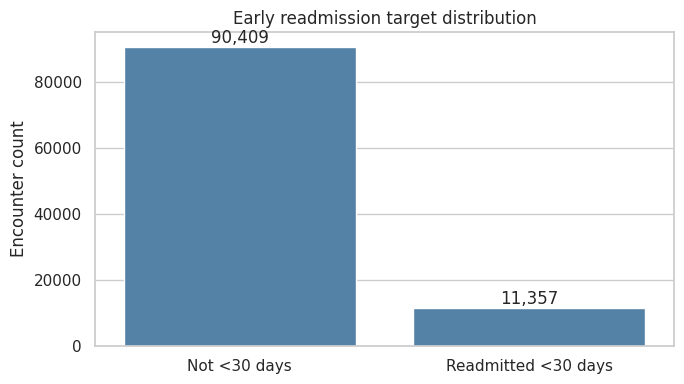

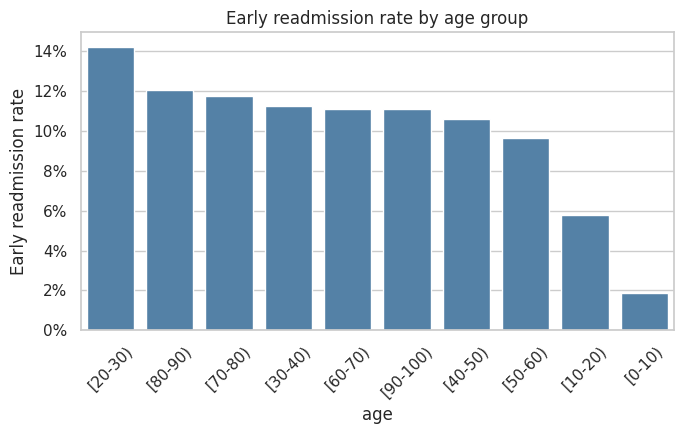

,age,early_readmission_rate,count
2,[20-30),0.1424,1657
8,[80-90),0.1208,17197
7,[70-80),0.1177,26068
3,[30-40),0.1123,3775
6,[60-70),0.1113,22483
9,[90-100),0.1110,2793
4,[40-50),0.1060,9685
5,[50-60),0.0967,17256
1,[10-20),0.0579,691
0,[0-10),0.0186,161


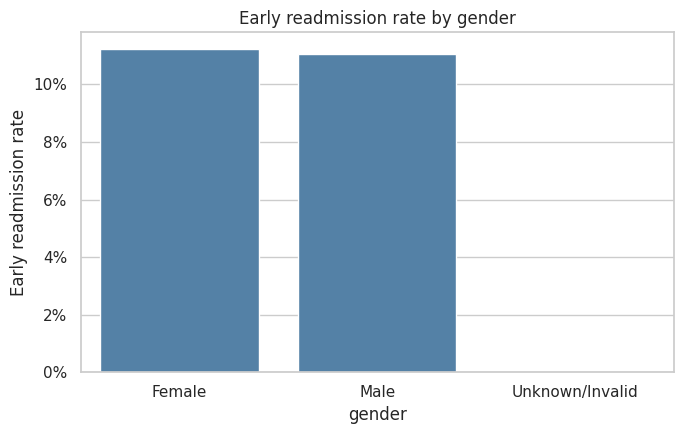

,gender,early_readmission_rate,count
0,Female,0.1125,54708
1,Male,0.1106,47055
2,Unknown/Invalid,0.0000,3


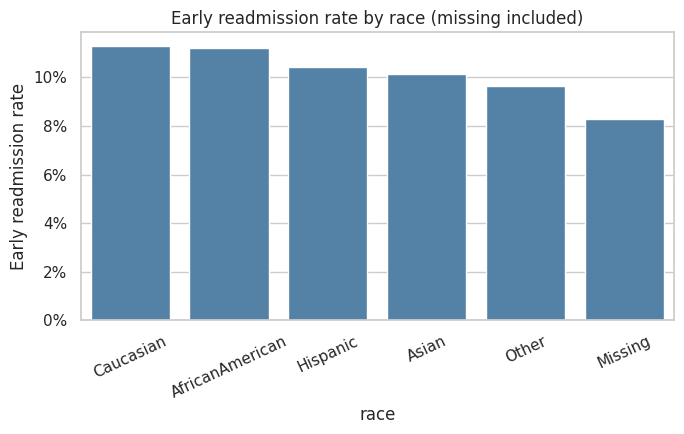

,race,early_readmission_rate,count
2,Caucasian,0.1129,76099
0,AfricanAmerican,0.1122,19210
3,Hispanic,0.1041,2037
1,Asian,0.1014,641
4,Other,0.0963,1506
5,Missing,0.0827,2273


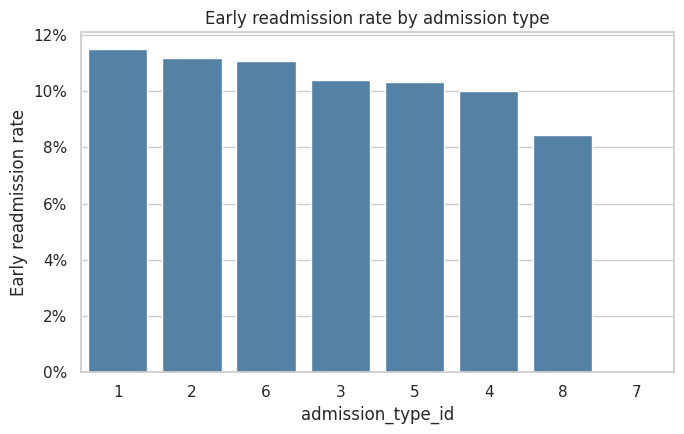

,admission_type_id,early_readmission_rate,count
0,1,0.1152,53990
1,2,0.1118,18480
5,6,0.1108,5291
2,3,0.1039,18869
4,5,0.1034,4785
3,4,0.1000,10
7,8,0.0844,320
6,7,0.0000,21


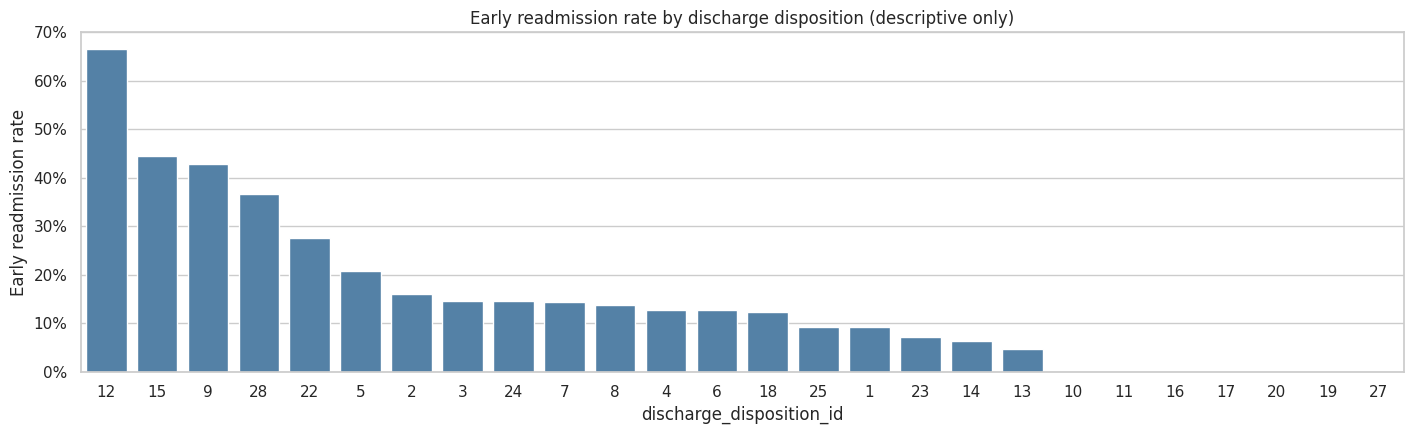

,discharge_disposition_id,early_readmission_rate,count
11,12,0.6667,3
14,15,0.4444,63
8,9,0.4286,21
25,28,0.3669,139
20,22,0.2770,1993
4,5,0.2086,1184
1,2,0.1607,2128
2,3,0.1466,13954
22,24,0.1458,48
6,7,0.1445,623


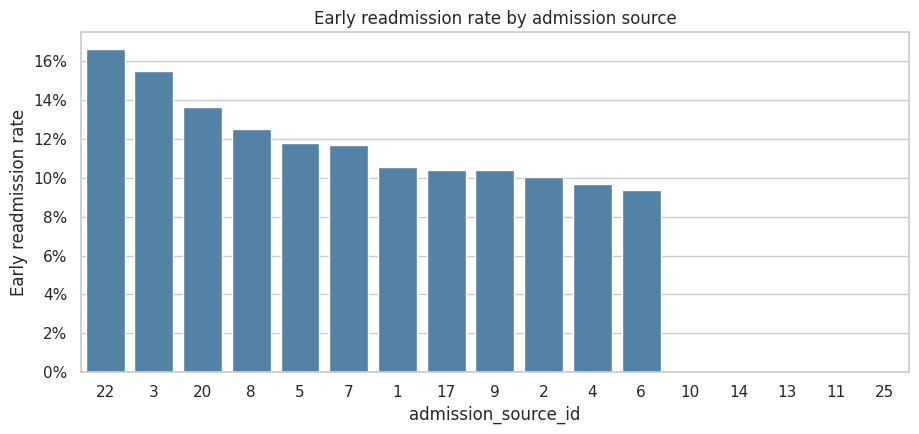

,admission_source_id,early_readmission_rate,count
15,22,0.1667,12
2,3,0.1551,187
14,20,0.1366,161
7,8,0.1250,16
4,5,0.1181,855
6,7,0.1169,57494
0,1,0.1059,29565
13,17,0.1041,6781
8,9,0.1040,125
1,2,0.1005,1104


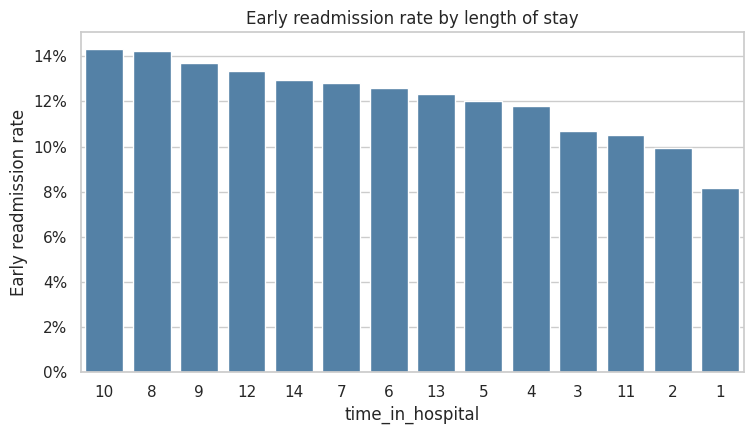

,time_in_hospital,early_readmission_rate,count
9,10,0.1435,2342
7,8,0.1423,4391
8,9,0.1372,3002
11,12,0.1333,1448
13,14,0.1296,1042
6,7,0.1283,5859
5,6,0.1259,7539
12,13,0.1231,1210
4,5,0.1203,9966
3,4,0.1181,13924


In [4]:
df["target_label"] = df["target"].map({0:"Not <30 days", 1:"Readmitted <30 days"})
fig, ax = plt.subplots(figsize=(7,4))
counts = df["target_label"].value_counts().reindex(["Not <30 days","Readmitted <30 days"])
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="steelblue")
ax.set(title="Early readmission target distribution", xlabel="", ylabel="Encounter count")
for i,v in enumerate(counts.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

def rate_plot(data, col, title, top_n=None, rotate=0):
    tmp = data.groupby(col, dropna=False)["target"].agg(["mean","count"]).reset_index()
    tmp[col] = tmp[col].astype("string").fillna("Missing")
    if top_n and len(tmp) > top_n:
        keep = tmp.nlargest(top_n, "count")[col]
        tmp = tmp[tmp[col].isin(keep)]
    tmp = tmp.sort_values("mean", ascending=False)
    fig, ax = plt.subplots(figsize=(max(7, len(tmp)*0.55), 4.5))
    sns.barplot(data=tmp, x=col, y="mean", ax=ax, color="steelblue")
    ax.set(title=title, xlabel=col, ylabel="Early readmission rate")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.tick_params(axis="x", rotation=rotate)
    plt.tight_layout(); plt.show()
    display(tmp.rename(columns={"mean":"early_readmission_rate"}).assign(
        early_readmission_rate=lambda x: x["early_readmission_rate"].round(4)))

for col, title, rot in [
    ("age","Early readmission rate by age group",45),
    ("gender","Early readmission rate by gender",0),
    ("race","Early readmission rate by race (missing included)",25),
    ("admission_type_id","Early readmission rate by admission type",0),
    ("discharge_disposition_id","Early readmission rate by discharge disposition (descriptive only)",0),
    ("admission_source_id","Early readmission rate by admission source",0),
]:
    rate_plot(df, col, title, rotate=rot)

rate_plot(df, "time_in_hospital", "Early readmission rate by length of stay")

/tmp/ipykernel_1043/1716265802.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp = data.groupby(col, dropna=False)["target"].agg(["mean","count"]).reset_index()


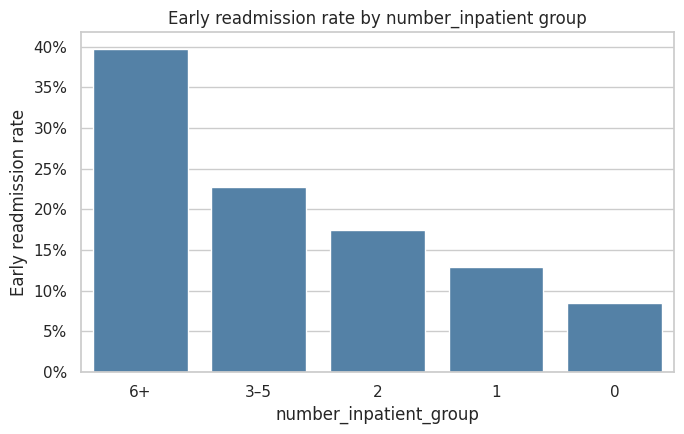

,number_inpatient_group,early_readmission_rate,count
4,6+,0.3978,1204
3,3–5,0.2275,5845
2,2,0.1743,7566
1,1,0.1292,19521
0,0,0.0844,67630


/tmp/ipykernel_1043/1716265802.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp = data.groupby(col, dropna=False)["target"].agg(["mean","count"]).reset_index()


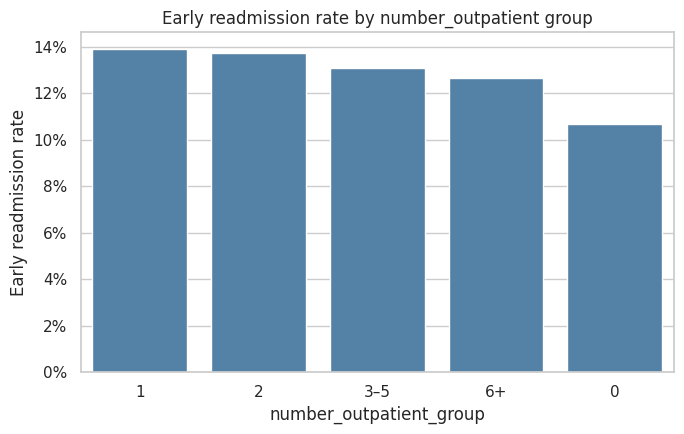

,number_outpatient_group,early_readmission_rate,count
1,1,0.1392,8547
2,2,0.1375,3594
3,3–5,0.1306,3674
4,6+,0.1266,924
0,0,0.1067,85027


/tmp/ipykernel_1043/1716265802.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp = data.groupby(col, dropna=False)["target"].agg(["mean","count"]).reset_index()


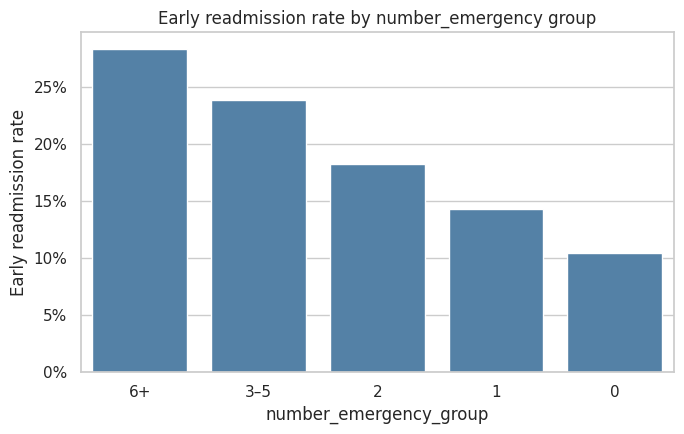

,number_emergency_group,early_readmission_rate,count
4,6+,0.2842,373
3,3–5,0.2393,1291
2,2,0.1827,2042
1,1,0.1435,7677
0,0,0.1047,90383


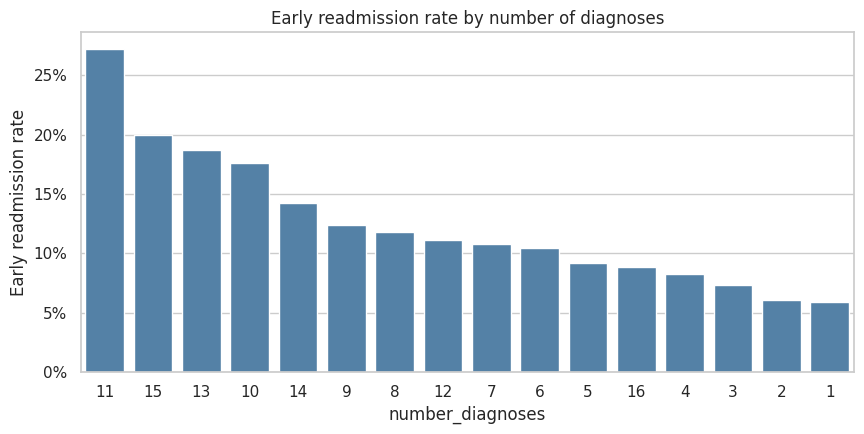

,number_diagnoses,early_readmission_rate,count
10,11,0.2727,11
14,15,0.2000,10
12,13,0.1875,16
9,10,0.1765,17
13,14,0.1429,7
8,9,0.1238,49474
7,8,0.1181,10616
11,12,0.1111,9
6,7,0.1077,10393
5,6,0.1041,10161


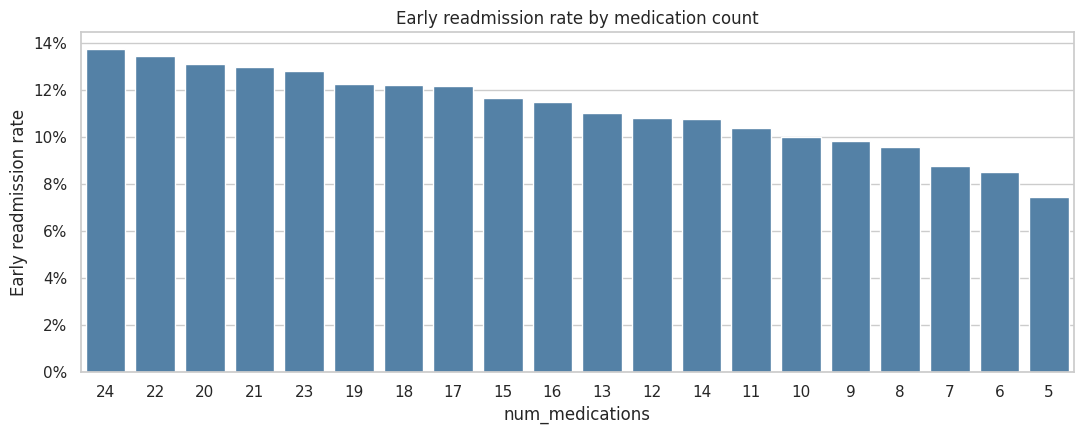

,num_medications,early_readmission_rate,count
23,24,0.1375,2109
21,22,0.1342,2868
19,20,0.1311,3691
20,21,0.1297,3230
22,23,0.1278,2426
18,19,0.1224,4078
17,18,0.1218,4523
16,17,0.1216,4919
14,15,0.1165,5792
15,16,0.1149,5430


time_in_hospital        num_lab_procedures        num_procedures  \
                   mean median               mean median           mean   
target                                                                    
0                  4.35    4.0              42.95   44.0           1.35   
1                  4.77    4.0              44.23   45.0           1.28   

              num_medications        number_outpatient         \
       median            mean median              mean median   
target                                                          
0         1.0           15.91   15.0              0.36    0.0   
1         1.0           16.90   16.0              0.44    0.0   

       number_emergency        number_inpatient        number_diagnoses         
                   mean median             mean median             mean median  
target                                                                          
0                  0.18    0.0             0.56    0.0             7.39    8.0  
1                  0.36    0.0             1.22    0.0             7.69    9.0

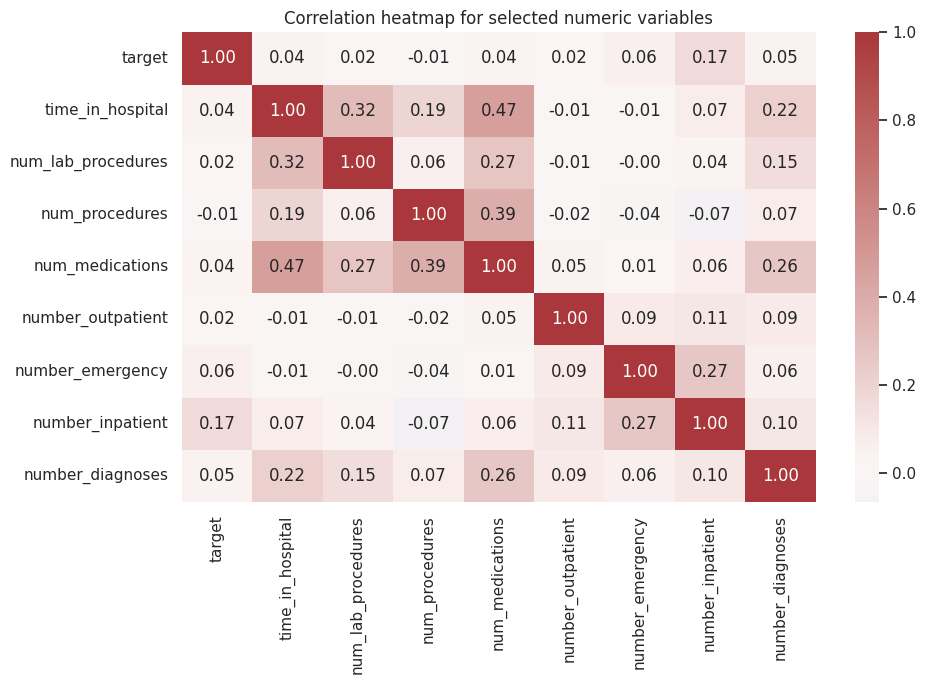

In [5]:
# Utilization groups and clinical/medication summaries
util_cols = ["number_inpatient","number_outpatient","number_emergency"]
for col in util_cols:
    df[f"{col}_group"] = pd.cut(df[col], bins=[-1,0,1,2,5,100],
        labels=["0","1","2","3–5","6+"], right=True)
    rate_plot(df, f"{col}_group", f"Early readmission rate by {col} group")

rate_plot(df, "number_diagnoses", "Early readmission rate by number of diagnoses")
rate_plot(df, "num_medications", "Early readmission rate by medication count", top_n=20)
display(df.groupby("target")[["time_in_hospital","num_lab_procedures","num_procedures","num_medications",
                              "number_outpatient","number_emergency","number_inpatient","number_diagnoses"]]
        .agg(["mean","median"]).round(2))

numeric_for_corr = ["target","time_in_hospital","num_lab_procedures","num_procedures","num_medications",
                    "number_outpatient","number_emergency","number_inpatient","number_diagnoses"]
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(df[numeric_for_corr].corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag",
            center=0, ax=ax)
ax.set_title("Correlation heatmap for selected numeric variables")
plt.tight_layout(); plt.show()

## 4. Leakage-aware preprocessing and patient-grouped partitions

- `encounter_id` and `patient_nbr` are excluded from predictive features; patient IDs are retained only for grouping.
- `readmitted` and the derived target are excluded from predictors.
- `discharge_disposition_id` is excluded because this primary experiment is framed as prediction before discharge disposition is finalized. This is a conservative prediction-time assumption; other remaining fields must still be interpreted according to when they are recorded.
- Split patients into train, validation, and test groups (approximately 64%/16%/20% of encounters). The validation partition is used for model selection. The test partition is kept untouched until one selected model is evaluated.
- Imputers, encoders, and scalers are fitted inside each model pipeline using training data only. Gradient Boosting receives a separate dense one-hot preprocessing pipeline for estimator compatibility.

For Gradient Boosting, infrequent categorical levels are grouped using `min_frequency=50` before dense one-hot encoding to keep the dense matrix manageable. This is a model-specific representation choice and is documented as such.

To keep dense `GradientBoostingClassifier` execution feasible in Colab, this candidate uses a reproducible maximum of 15,000 rows sampled from the training partition only (40 boosting stages). All models are scored on the same full patient-grouped validation partition. This computational compromise is explicitly documented and means training data volume differs for this candidate.

In [6]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from scipy import sparse

excluded = {"encounter_id", "patient_nbr", "readmitted", "target", "target_label",
            "discharge_disposition_id", "weight"}
excluded.update([c for c in df.columns if c.endswith("_group")])
feature_cols = [c for c in df.columns if c not in excluded]
X_raw = df[feature_cols].copy()
y = df["target"].astype(int).copy()
groups = df["patient_nbr"].copy()

numeric_cols = X_raw.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", num_pipe, numeric_cols), ("cat", cat_pipe, categorical_cols)])
# GradientBoostingClassifier requires dense input. Keep this pipeline separate so other estimators can use sparse OHE.
try:
    dense_ohe = OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False)
except TypeError:  # scikit-learn < 1.2
    dense_ohe = OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse=False)
dense_cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", dense_ohe)])
dense_preprocessor = ColumnTransformer([("num", num_pipe, numeric_cols), ("cat", dense_cat_pipe, categorical_cols)])

# First reserve 20% of patients for final test. From remaining patients reserve 20% for validation.
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(outer.split(X_raw, y, groups=groups))
inner = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + 1)
tr_rel, va_rel = next(inner.split(X_raw.iloc[trainval_idx], y.iloc[trainval_idx], groups=groups.iloc[trainval_idx]))
train_idx = trainval_idx[tr_rel]
val_idx = trainval_idx[va_rel]
X_train_raw, X_val_raw, X_test_raw = X_raw.iloc[train_idx], X_raw.iloc[val_idx], X_raw.iloc[test_idx]
y_train, y_val, y_test = y.iloc[train_idx], y.iloc[val_idx], y.iloc[test_idx]
groups_train, groups_val, groups_test = groups.iloc[train_idx], groups.iloc[val_idx], groups.iloc[test_idx]
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))
for label, target_part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    if target_part.nunique() < 2:
        raise ValueError(f"Patient-grouped {label} partition does not contain both classes; revise split transparently.")
print("Features:", len(feature_cols), "| numeric:", len(numeric_cols), "| categorical:", len(categorical_cols))
for label, Xp, yp, gp in [("Train", X_train_raw, y_train, groups_train), ("Validation", X_val_raw, y_val, groups_val), ("Test (untouched until final evaluation)", X_test_raw, y_test, groups_test)]:
    print(f"{label}: encounters={len(Xp):,}; patients={gp.nunique():,}; class counts={yp.value_counts().sort_index().to_dict()}; positive rate={yp.mean():.4f}")
print("Pairwise patient overlaps:", len(set(groups_train)&set(groups_val)), len(set(groups_train)&set(groups_test)), len(set(groups_val)&set(groups_test)))


Features: 45 | numeric: 10 | categorical: 35
Train: encounters=65,243; patients=45,771; class counts={0: 57882, 1: 7361}; positive rate=0.1128
Validation: encounters=16,370; patients=11,443; class counts={0: 14525, 1: 1845}; positive rate=0.1127
Test (untouched until final evaluation): encounters=20,153; patients=14,304; class counts={0: 18002, 1: 2151}; positive rate=0.1067
Pairwise patient overlaps: 0 0 0


## 5. Train models and select using validation data only

Every candidate is fitted on the training partition and scored on validation only. The test partition is not used for model selection, threshold tuning, or comparison charts. Gradient Boosting uses dense one-hot encoding; other models use sparse one-hot encoding. Failures are recorded explicitly.

**Compute note:** Gradient Boosting uses a dense one-hot matrix with infrequent categories grouped (`min_frequency=50`) and a reproducible training-only subsample of up to 15,000 rows; its validation metrics use the same full validation partition as other models.

The final classification threshold is tuned on the selected model’s validation scores by maximizing validation F1 (recall is the tie-breaker). The test partition is not used for threshold selection.

In [7]:
models = {
    "Dummy (prior)": (DummyClassifier(strategy="prior"), preprocessor),
    "Logistic Regression": (LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED), preprocessor),
    "Decision Tree": (DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=SEED), preprocessor),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED), preprocessor),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=200, max_depth=16, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=SEED), preprocessor),
    "Gradient Boosting": (GradientBoostingClassifier(n_estimators=40, learning_rate=0.05, max_depth=2, random_state=SEED), dense_preprocessor),
}
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = (XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.9,
        colsample_bytree=0.9, eval_metric="logloss", random_state=SEED, n_jobs=4), preprocessor)
    print("XGBoost available:", __import__("xgboost").__version__)
except Exception as exc:
    print("XGBoost unavailable; not run:", type(exc).__name__, str(exc))

fitted = {}
validation_predictions = {}
validation_scores = {}
validation_rows = []
model_execution_status = []
def metric_row(name, y_true, pred, score):
    return {"Model": name, "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, score) if pd.Series(y_true).nunique()==2 else np.nan,
        "PR-AUC (Average Precision)": average_precision_score(y_true, score) if pd.Series(y_true).nunique()==2 else np.nan,
        "Confusion matrix [TN, FP, FN, TP]": tuple(confusion_matrix(y_true, pred, labels=[0,1]).ravel())}

for name, (estimator, prep) in models.items():
    print("\nTraining:", name)
    pipe = Pipeline([("preprocess", prep), ("model", estimator)])
    try:
        if name == "Gradient Boosting" and len(X_train_raw) > 15000:
            gb_idx = np.random.RandomState(SEED).choice(len(X_train_raw), size=15000, replace=False)
            X_fit, y_fit = X_train_raw.iloc[gb_idx], y_train.iloc[gb_idx]
        else:
            X_fit, y_fit = X_train_raw, y_train
        pipe.fit(X_fit, y_fit)
        pred = pipe.predict(X_val_raw)
        if hasattr(pipe, "predict_proba"):
            score = pipe.predict_proba(X_val_raw)[:, 1]
        elif hasattr(pipe, "decision_function"):
            score = pipe.decision_function(X_val_raw)
        else:
            score = pred.astype(float)
        fitted[name] = pipe
        validation_predictions[name] = pred
        validation_scores[name] = score
        validation_rows.append(metric_row(name, y_val, pred, score))
        model_execution_status.append({"Model":name,"Status":"SUCCESS","Error":None})
        print("SUCCESS; validation AP:", round(validation_rows[-1]["PR-AUC (Average Precision)"], 5), "| training rows:", len(X_fit))
    except Exception as exc:
        model_execution_status.append({"Model":name,"Status":"FAILED","Error":f"{type(exc).__name__}: {exc}"})
        print(f"FAILED {name}: {type(exc).__name__}: {exc}")

validation_results = pd.DataFrame(validation_rows)
execution_status = pd.DataFrame(model_execution_status)
print("\nModel execution status:")
display(execution_status)
if validation_results.empty:
    raise RuntimeError("No model completed successfully. Do not report experimental metrics.")
display(validation_results.sort_values(["PR-AUC (Average Precision)", "Recall"], ascending=False).round(4))
# Predeclared validation-only selection: highest average precision, recall tie-breaker.
best_row = validation_results.sort_values(["PR-AUC (Average Precision)", "Recall"], ascending=False).iloc[0]
best_name = best_row["Model"]
print("Selected using validation data only:", best_name)
# Tune the classification threshold using validation predictions only; maximize F1, then recall.
sel_score = validation_scores[best_name]
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_val, sel_score)
if len(pr_thresholds):
    val_f1 = 2 * pr_precision[:-1] * pr_recall[:-1] / np.maximum(pr_precision[:-1] + pr_recall[:-1], 1e-12)
    threshold_idx = np.lexsort((pr_recall[:-1], val_f1))[-1]
    selected_threshold = float(pr_thresholds[threshold_idx])
    print("Threshold selected from validation only:", round(selected_threshold, 6),
          "| validation F1:", round(float(val_f1[threshold_idx]), 4),
          "| validation recall:", round(float(pr_recall[threshold_idx]), 4))
else:
    selected_threshold = 0.5
    print("No validation thresholds available; default threshold 0.5 used.")
selected_val_pred = (sel_score >= selected_threshold).astype(int)
selected_validation_threshold_results = pd.DataFrame([metric_row(best_name, y_val, selected_val_pred, sel_score)])
selected_validation_threshold_results.insert(1, "Threshold", selected_threshold)
print("Selected model validation metrics at the frozen threshold:")
display(selected_validation_threshold_results.round(4))


XGBoost available: 3.4.1

Training: Dummy (prior)
SUCCESS; validation AP: 0.11271 | training rows: 65243

Training: Logistic Regression
SUCCESS; validation AP: 0.2082 | training rows: 65243

Training: Decision Tree
SUCCESS; validation AP: 0.18746 | training rows: 65243

Training: Random Forest
SUCCESS; validation AP: 0.19361 | training rows: 65243

Training: Extra Trees
SUCCESS; validation AP: 0.18882 | training rows: 65243

Training: Gradient Boosting
SUCCESS; validation AP: 0.19938 | training rows: 15000

Training: XGBoost
SUCCESS; validation AP: 0.21361 | training rows: 65243

Model execution status:


,Model,Status,Error
0,Dummy (prior),SUCCESS,None
1,Logistic Regression,SUCCESS,None
2,Decision Tree,SUCCESS,None
3,Random Forest,SUCCESS,None
4,Extra Trees,SUCCESS,None
5,Gradient Boosting,SUCCESS,None
6,XGBoost,SUCCESS,None


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),"Confusion matrix [TN, FP, FN, TP]"
6,XGBoost,0.8870,0.4375,0.0076,0.0149,0.6610,0.2136,"(14507, 18, 1831, 14)"
1,Logistic Regression,0.6346,0.1661,0.5577,0.2560,0.6388,0.2082,"(9360, 5165, 816, 1029)"
5,Gradient Boosting,0.8873,0.0000,0.0000,0.0000,0.6450,0.1994,"(14525, 0, 1845, 0)"
3,Random Forest,0.6398,0.1693,0.5621,0.2602,0.6516,0.1936,"(9437, 5088, 808, 1037)"
4,Extra Trees,0.5782,0.1498,0.5864,0.2386,0.6242,0.1888,"(8383, 6142, 763, 1082)"
2,Decision Tree,0.5726,0.1535,0.6184,0.2460,0.6338,0.1875,"(8233, 6292, 704, 1141)"
0,Dummy (prior),0.8873,0.0000,0.0000,0.0000,0.5000,0.1127,"(14525, 0, 1845, 0)"


Selected using validation data only: XGBoost
Threshold selected from validation only: 0.134883 | validation F1: 0.272 | validation recall: 0.4081
Selected model validation metrics at the frozen threshold:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),"Confusion matrix [TN, FP, FN, TP]"
0,XGBoost,0.1349,0.7538,0.204,0.4081,0.272,0.661,0.2136,"(11587, 2938, 1092, 753)"


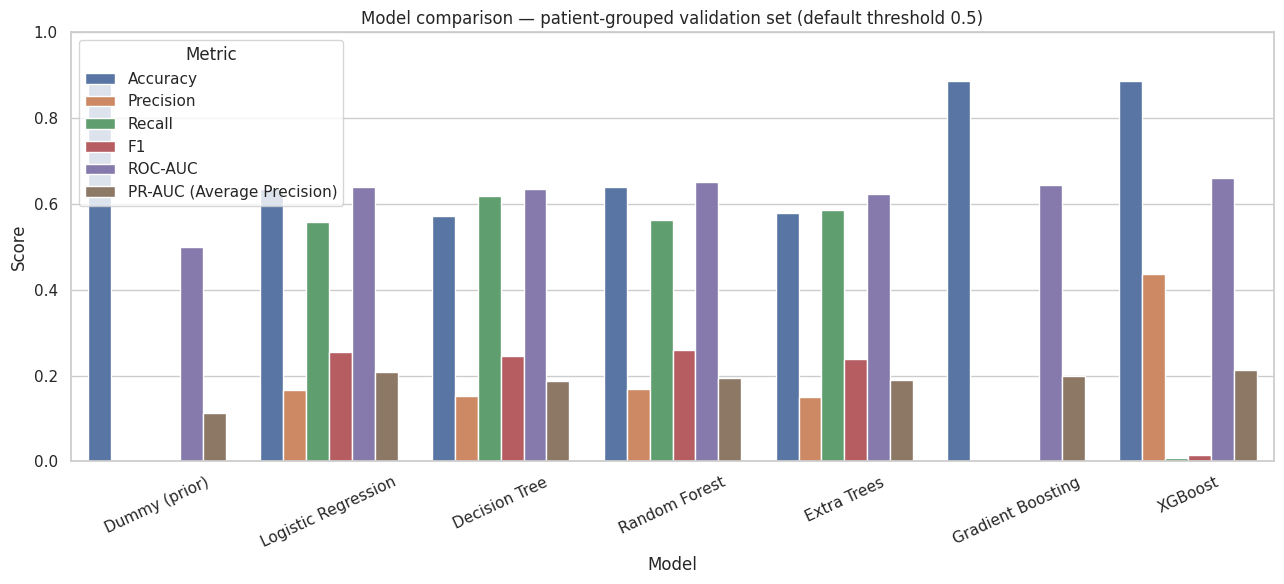

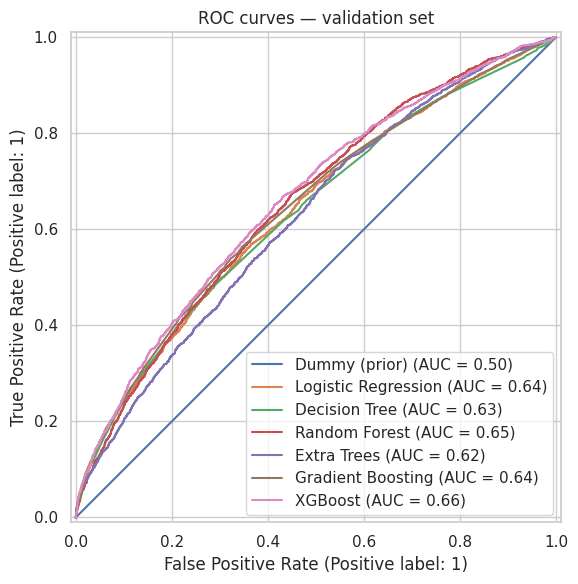

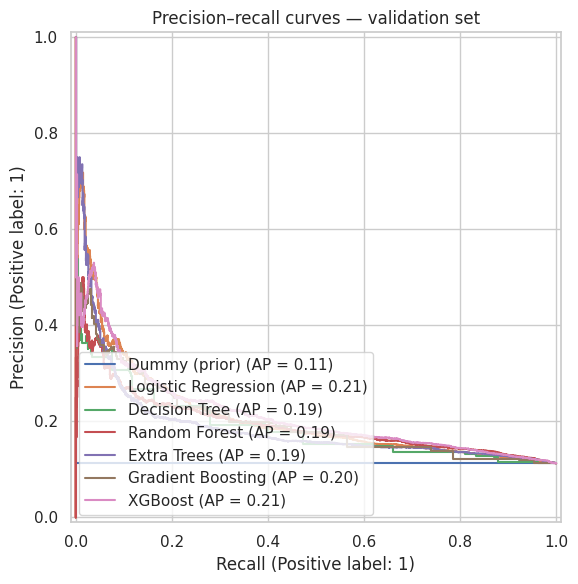

FINAL TEST METRICS — selected model evaluated once on untouched patient-grouped test set; threshold was selected on validation data
Frozen threshold from validation: 0.13488315045833588


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),"Confusion matrix [TN, FP, FN, TP]"
0,XGBoost,0.7559,0.1902,0.3952,0.2568,0.648,0.1928,"(14384, 3618, 1301, 850)"


                              precision    recall  f1-score   support

       Not early readmission       0.92      0.80      0.85     18002
Early readmission (<30 days)       0.19      0.40      0.26      2151

                    accuracy                           0.76     20153
                   macro avg       0.55      0.60      0.56     20153
                weighted avg       0.84      0.76      0.79     20153



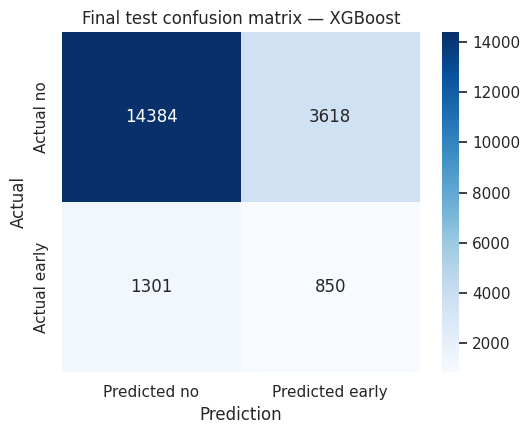

Test-set integrity: candidate selection used validation only; no candidate test comparison was performed.


In [8]:
# Candidate comparison and ranking curves use validation data only.
plot_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC (Average Precision)"]
results_long = validation_results.melt(id_vars="Model", value_vars=plot_metrics, var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13,6))
sns.barplot(data=results_long, x="Model", y="Score", hue="Metric", ax=ax, palette="deep")
ax.set_ylim(0,1); ax.set_title("Model comparison — patient-grouped validation set (default threshold 0.5)")
ax.tick_params(axis="x", rotation=25); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,6))
for name, score in validation_scores.items(): RocCurveDisplay.from_predictions(y_val, score, name=name, ax=ax)
ax.set_title("ROC curves — validation set"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,6))
for name, score in validation_scores.items(): PrecisionRecallDisplay.from_predictions(y_val, score, name=name, ax=ax)
ax.set_title("Precision–recall curves — validation set"); plt.tight_layout(); plt.show()

# Finalize the selected pipeline using train + validation only, then evaluate once on untouched test data.
from sklearn.base import clone
X_trainval_raw = pd.concat([X_train_raw, X_val_raw], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)
selected_estimator, selected_preprocessor = models[best_name]
best_model = Pipeline([("preprocess", clone(selected_preprocessor)), ("model", clone(selected_estimator))])
best_model.fit(X_trainval_raw, y_trainval)
if hasattr(best_model, "predict_proba"):
    best_test_score = best_model.predict_proba(X_test_raw)[:, 1]
elif hasattr(best_model, "decision_function"):
    best_test_score = best_model.decision_function(X_test_raw)
else:
    best_test_score = best_model.predict(X_test_raw).astype(float)
best_pred = (best_test_score >= selected_threshold).astype(int)
test_results = pd.DataFrame([metric_row(best_name, y_test, best_pred, best_test_score)])
print("FINAL TEST METRICS — selected model evaluated once on untouched patient-grouped test set; threshold was selected on validation data")
print("Frozen threshold from validation:", selected_threshold)
display(test_results.round(4))
print(classification_report(y_test, best_pred, target_names=["Not early readmission", "Early readmission (<30 days)"], zero_division=0))
cm = confusion_matrix(y_test, best_pred, labels=[0,1])
fig, ax = plt.subplots(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Predicted no", "Predicted early"],
            yticklabels=["Actual no", "Actual early"], ax=ax)
ax.set_title(f"Final test confusion matrix — {best_name}"); ax.set_xlabel("Prediction"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
print("Test-set integrity: candidate selection used validation only; no candidate test comparison was performed.")


### Clinical interpretation of classification errors

- **False negative:** an encounter that is actually followed by readmission within 30 days but is predicted negative. In a clinical workflow this could mean missing an encounter that might warrant further review.
- **False positive:** an encounter predicted as early readmission but not in the positive class. This can create unnecessary review workload.
- Neither error establishes that an intervention would or would not prevent readmission. Model outputs are risk estimates, not diagnoses or treatment recommendations.

## 6. Explainability

Random Forest impurity importance and permutation importance describe model behavior, not causal effects. Permutation importance and optional SHAP explanations use validation/training data rather than the untouched test partition. Failure of an optional explanation is reported explicitly.

,Feature,Importance
8,num__number_inpatient,0.043114
786,cat__diag_1_V58,0.008935
785,cat__diag_1_V57,0.008432
383,cat__diag_1_434,0.008216
664,cat__diag_1_820,0.008083
377,cat__diag_1_428,0.007795
208,cat__diag_1_250.13,0.007652
226,cat__diag_1_250.7,0.007356
7,num__number_emergency,0.006860
1227,cat__diag_2_707,0.006466


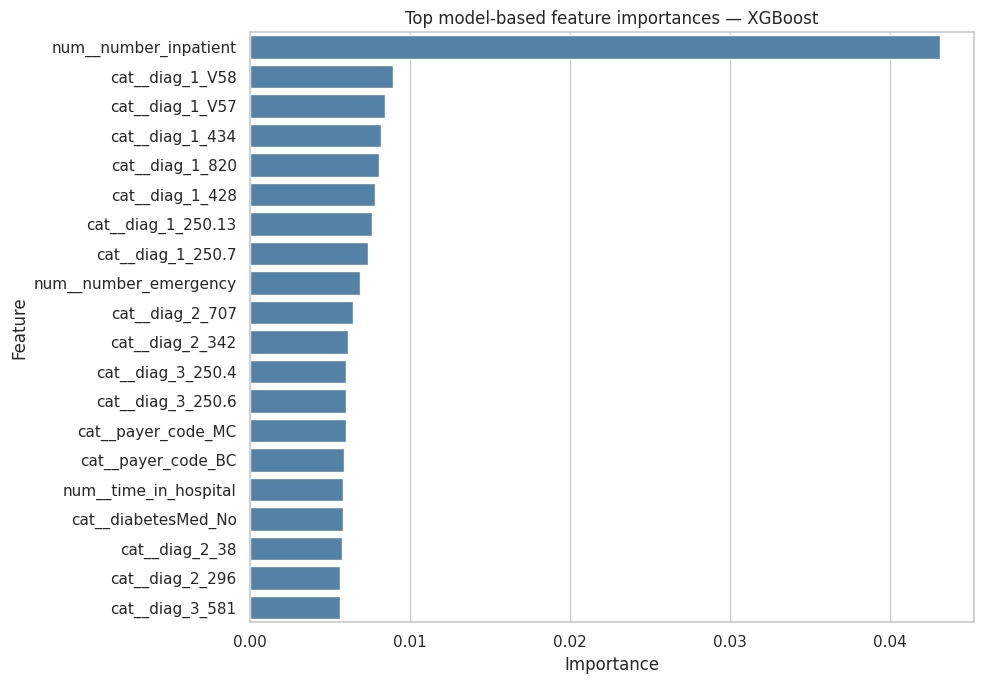

,Feature,Importance
13,number_inpatient,0.057957
14,diag_1,0.010895
12,number_emergency,0.003748
44,diabetesMed,0.001893
2,age,0.001864
5,time_in_hospital,0.000980
9,num_procedures,0.000844
43,change,0.000720
6,payer_code,0.000670
4,admission_source_id,0.000486


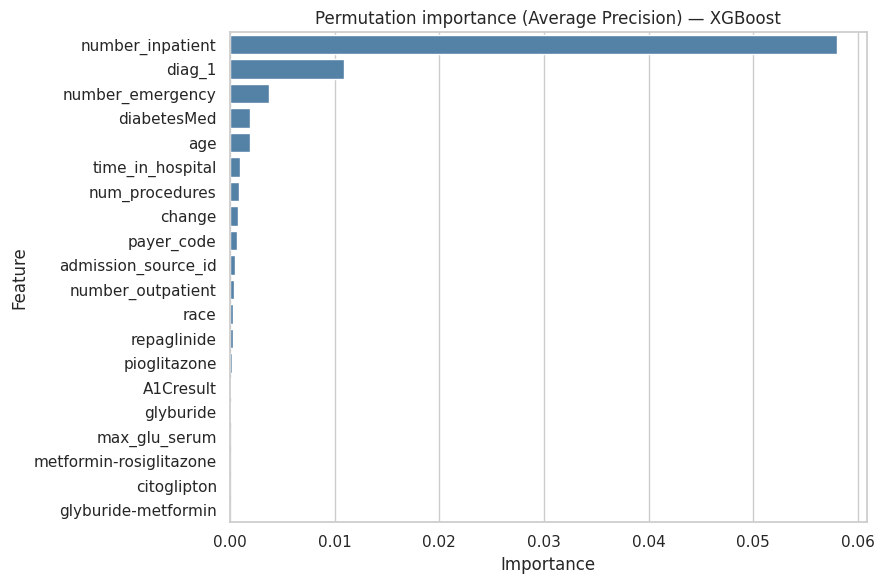

SHAP version: 0.54.1
Generated SHAP values of shape: (200, 2288)


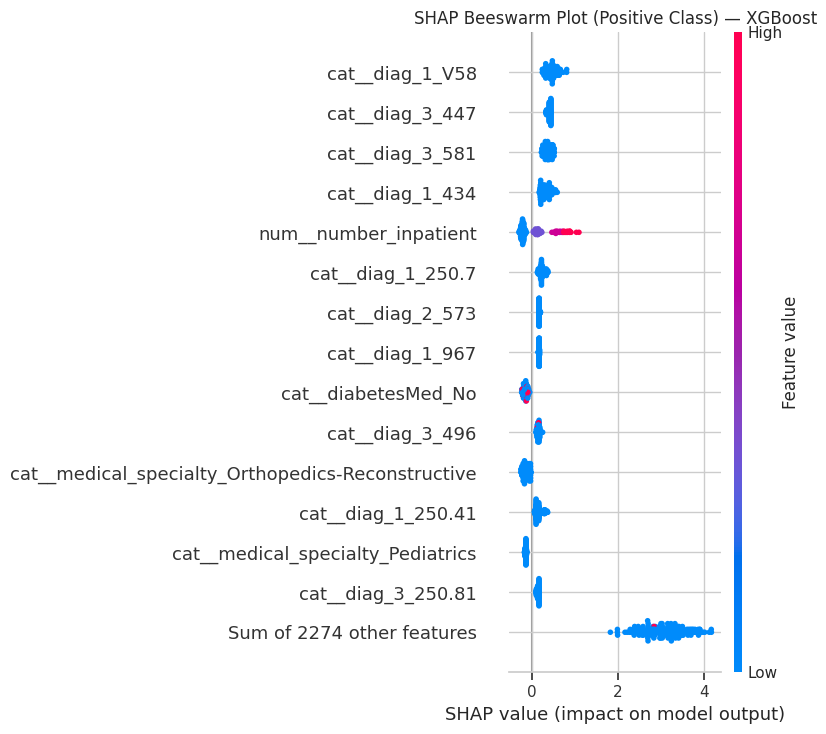

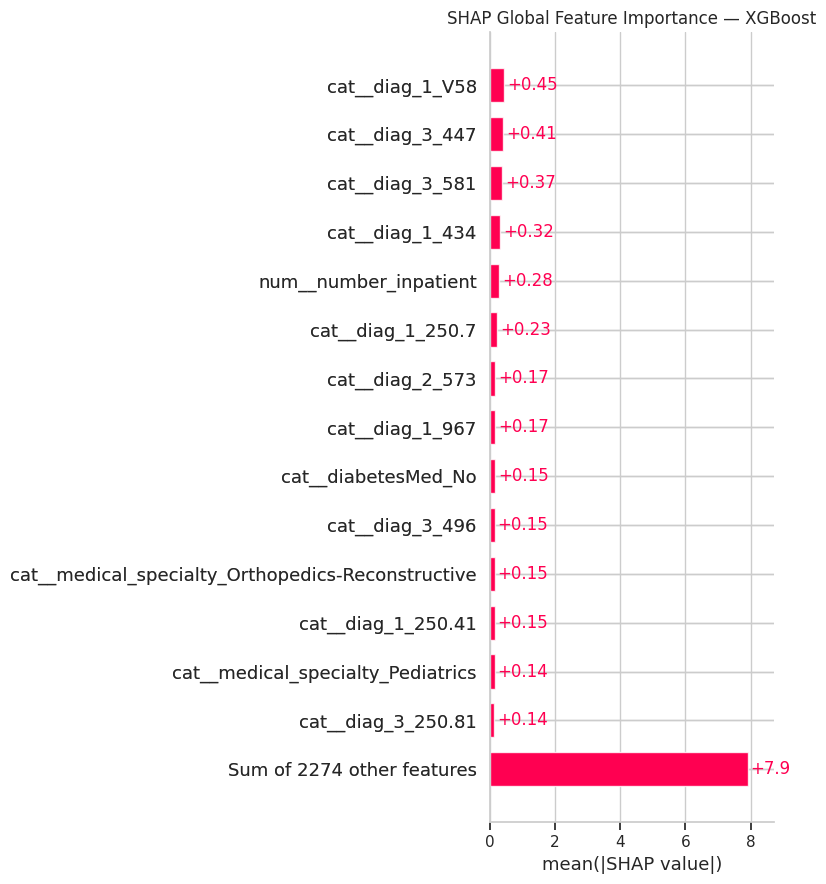


Generating waterfall plot for first sample in the validation subset:


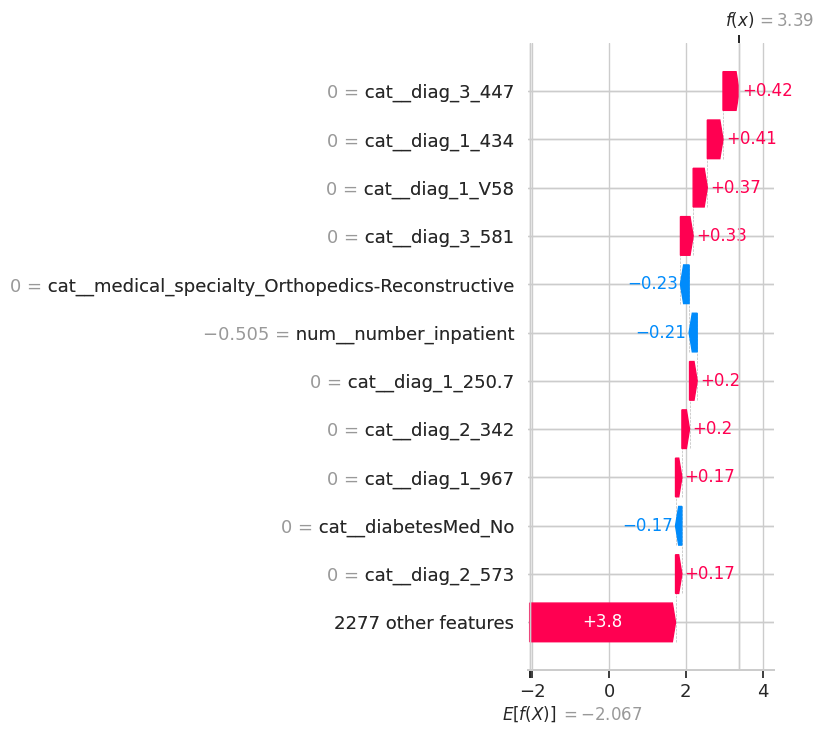

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# Extract feature names and model-based importance if supported.
explanation_model = fitted[best_name]  # trained on train partition only; validation remains the explanation/evaluation sample
fitted_pre = explanation_model.named_steps["preprocess"]
feature_names_out = fitted_pre.get_feature_names_out()
core_estimator = explanation_model.named_steps["model"]

if hasattr(core_estimator, "feature_importances_"):
    imp = pd.DataFrame({"Feature": feature_names_out, "Importance": core_estimator.feature_importances_})
    imp = imp.sort_values("Importance", ascending=False).head(20)
    display(imp)
    fig, ax = plt.subplots(figsize=(10,7))
    sns.barplot(data=imp, x="Importance", y="Feature", ax=ax, color="steelblue")
    ax.set_title(f"Top model-based feature importances — {best_name}")
    plt.tight_layout(); plt.show()
else:
    print(f"{best_name} does not expose native feature_importances_. Use permutation importance below.")

try:
    # Use a reproducible subsample to limit runtime.
    n_perm = min(2000, len(X_val_raw))
    perm_idx = np.random.RandomState(SEED).choice(len(X_val_raw), size=n_perm, replace=False)
    # best_model was refit on train+validation; for strict separation, report this as descriptive validation-sample permutation analysis only.
    perm = permutation_importance(explanation_model, X_val_raw.iloc[perm_idx], y_val.iloc[perm_idx],
        scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
    perm_df = pd.DataFrame({"Feature": X_raw.columns, "Importance": perm.importances_mean})
    perm_df = perm_df.sort_values("Importance", ascending=False).head(20)
    display(perm_df)
    fig, ax = plt.subplots(figsize=(9,6))
    sns.barplot(data=perm_df, x="Importance", y="Feature", ax=ax, color="steelblue")
    ax.set_title(f"Permutation importance (Average Precision) — {best_name}")
    plt.tight_layout(); plt.show()
except Exception as exc:
    print("Permutation importance failed:", type(exc).__name__, str(exc))

try:
    import shap
    print("SHAP version:", shap.__version__)

    # 1. Sample validation data reproducibly to avoid high computation times
    n_shap_samples = min(200, len(X_val_raw))
    shap_sample_idx = np.random.RandomState(SEED).choice(len(X_val_raw), size=n_shap_samples, replace=False)
    X_shap_raw = X_val_raw.iloc[shap_sample_idx]

    # 2. Transform the raw features using the fitted preprocessor so they are purely numeric
    X_shap_transformed = fitted_pre.transform(X_shap_raw)
    if hasattr(X_shap_transformed, "toarray"): # if sparse, convert to dense
        X_shap_transformed = X_shap_transformed.toarray()

    # 3. Create a DataFrame with the matched out-of-preprocessor feature names
    # XGBoost forbids '[', ']', and '<' in feature names; replace them with safe underscores
    sanitized_feature_names = [
        name.replace("[", "_").replace("]", "_").replace("<", "_lt_").replace(">", "_gt_")
        for name in feature_names_out
    ]
    X_shap_df = pd.DataFrame(X_shap_transformed, columns=sanitized_feature_names, index=X_shap_raw.index)

    # 4. Use TreeExplainer (optimized for XGBoost/Trees) directly on the preprocessed data
    explainer = shap.TreeExplainer(core_estimator)
    shap_values = explainer(X_shap_df)

    # 5. Handle binary-classification SHAP output dimensions safely
    # If shap_values has 3 dimensions [samples, features, classes], select positive class (index 1)
    if len(shap_values.shape) == 3:
        shap_values_class = shap_values[:, :, 1]
    else:
        shap_values_class = shap_values

    print(f"Generated SHAP values of shape: {shap_values_class.shape}")

    # 6. SHAP Summary Beeswarm Plot
    plt.figure(figsize=(10, 6))
    plt.title(f"SHAP Beeswarm Plot (Positive Class) — {best_name}")
    shap.plots.beeswarm(shap_values_class, max_display=15, show=False)
    plt.tight_layout(); plt.show()

    # 7. SHAP Global Feature Importance Bar Plot
    plt.figure(figsize=(10, 6))
    plt.title(f"SHAP Global Feature Importance — {best_name}")
    shap.plots.bar(shap_values_class, max_display=15, show=False)
    plt.tight_layout(); plt.show()

    # 8. SHAP Waterfall Plot for a single predicted test encounter
    print("\nGenerating waterfall plot for first sample in the validation subset:")
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values_class[0], max_display=12, show=False)
    plt.tight_layout(); plt.show()

except Exception as exc:
    import traceback
    print("SHAP failed:", type(exc).__name__, str(exc))
    print(traceback.format_exc())


## 7. Prediction interface (academic demonstration)

The interface uses the selected model fitted on train + validation and its exact preprocessing pipeline. Default values are copied from an actual training encounter for demonstration only. This is an academic prototype, not a clinically validated medical decision system.

In [10]:
# A safe, minimal ipywidgets form over raw model input columns.
import ipywidgets as widgets
from IPython.display import display, clear_output

demo_row = X_train_raw.iloc[0].copy()
controls = {}
for col in feature_cols:
    if col in numeric_cols:
        val = demo_row[col]
        if pd.isna(val): val = 0
        controls[col] = widgets.FloatText(value=float(val), description=col[:18], layout=widgets.Layout(width="350px"))
    else:
        vals = sorted(X_train_raw[col].dropna().astype(str).unique().tolist())
        opts = vals if vals else ["Unknown"]
        val = str(demo_row[col]) if pd.notna(demo_row[col]) else opts[0]
        if val not in opts: opts = [val] + opts
        controls[col] = widgets.Dropdown(options=opts, value=val, description=col[:18],
                                         layout=widgets.Layout(width="350px"))
button = widgets.Button(description="Predict", button_style="primary")
out = widgets.Output()
def on_predict(_):
    with out:
        clear_output()
        try:
            row = {}
            for col, w in controls.items():
                row[col] = w.value
            inp = pd.DataFrame([row], columns=feature_cols)
            pred = int(best_model.predict(inp)[0])
            print("Predicted class:", "Early readmission (<30 days)" if pred == 1 else "Not early readmission")
            if hasattr(best_model, "predict_proba"):
                print("Predicted probability of early readmission:", f"{best_model.predict_proba(inp)[0,1]:.3f}")
            print("\nDISCLAIMER: Academic prototype only. Not clinically validated. Do not use for diagnosis, treatment, or care decisions.")
        except Exception as exc:
            print("Prediction could not be generated. Check input values.", type(exc).__name__, str(exc))
button.on_click(on_predict)
display(widgets.VBox([widgets.HTML("<b>Academic early-readmission prediction demo</b>"),
                      widgets.GridBox(list(controls.values()), layout=widgets.Layout(grid_template_columns="repeat(2, 370px)")),
                      button, out]))

## 8. Final validation and reproducibility record

This section records actual runtime versions, dimensions, split sizes, target counts, leakage checks, and errors. Successful execution is only established if all cells complete without errors in the runtime used for submission.

In [11]:
import sklearn
print("Python:", sys.version)
print("Platform:", platform.platform())
print("pandas:", pd.__version__, "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("Available hardware: CPU count =", os.cpu_count())
try:
    import psutil
    print("RAM total (GB):", round(psutil.virtual_memory().total/1e9, 2))
except Exception: print("RAM information unavailable.")
print("Dataset shape:", df_raw.shape, "| unique patients:", df_raw["patient_nbr"].nunique())
print("Split encounter sizes:", {"train":len(X_train_raw), "validation":len(X_val_raw), "test":len(X_test_raw)})
print("Split patient counts:", {"train":groups_train.nunique(), "validation":groups_val.nunique(), "test":groups_test.nunique()})
print("Patient overlaps:", {"train-validation":len(set(groups_train)&set(groups_val)), "train-test":len(set(groups_train)&set(groups_test)), "validation-test":len(set(groups_val)&set(groups_test))})
print("Target leakage check:", not any(c in feature_cols for c in ["readmitted", "target"]))
print("Identifier leakage check:", not any(c in feature_cols for c in ["encounter_id", "patient_nbr"]))
print("Discharge disposition excluded:", "discharge_disposition_id" not in feature_cols)
print("Preprocessing fit only inside training pipeline during candidate selection: yes; final selected pipeline fit on train+validation only.")
print("Random seed:", SEED)
print("Model hyperparameters:")
for name, (est, prep) in models.items(): print(name, est.get_params())
print("\nModel execution results:"); display(execution_status)
print("\nValidation results (used for model selection; default threshold 0.5):"); display(validation_results.round(4))
print("\nSelected-model validation metrics at frozen threshold:"); display(selected_validation_threshold_results.round(4))
print("Frozen validation-selected threshold:", selected_threshold)
print("\nFinal test results (selected model only):"); display(test_results.round(4))
assert len(set(groups_train)&set(groups_val)) == 0
assert len(set(groups_train)&set(groups_test)) == 0
assert len(set(groups_val)&set(groups_test)) == 0
assert not any(c in feature_cols for c in ["readmitted", "target", "encounter_id", "patient_nbr"])
print("Structural validation checks passed. Full notebook execution status depends on whether all cells above completed without error in this runtime.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
pandas: 2.2.3 | NumPy: 2.1.3 | scikit-learn: 1.6.1
Available hardware: CPU count = 2
RAM total (GB): 13.61
Dataset shape: (101766, 50) | unique patients: 71518
Split encounter sizes: {'train': 65243, 'validation': 16370, 'test': 20153}
Split patient counts: {'train': 45771, 'validation': 11443, 'test': 14304}
Patient overlaps: {'train-validation': 0, 'train-test': 0, 'validation-test': 0}
Target leakage check: True
Identifier leakage check: True
Discharge disposition excluded: True
Preprocessing fit only inside training pipeline during candidate selection: yes; final selected pipeline fit on train+validation only.
Random seed: 42
Model hyperparameters:
Dummy (prior) {'constant': None, 'random_state': None, 'strategy': 'prior'}
Logistic Regression {'C': 1.0, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1500, 

,Model,Status,Error
0,Dummy (prior),SUCCESS,None
1,Logistic Regression,SUCCESS,None
2,Decision Tree,SUCCESS,None
3,Random Forest,SUCCESS,None
4,Extra Trees,SUCCESS,None
5,Gradient Boosting,SUCCESS,None
6,XGBoost,SUCCESS,None



Validation results (used for model selection; default threshold 0.5):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),"Confusion matrix [TN, FP, FN, TP]"
0,Dummy (prior),0.8873,0.0000,0.0000,0.0000,0.5000,0.1127,"(14525, 0, 1845, 0)"
1,Logistic Regression,0.6346,0.1661,0.5577,0.2560,0.6388,0.2082,"(9360, 5165, 816, 1029)"
2,Decision Tree,0.5726,0.1535,0.6184,0.2460,0.6338,0.1875,"(8233, 6292, 704, 1141)"
3,Random Forest,0.6398,0.1693,0.5621,0.2602,0.6516,0.1936,"(9437, 5088, 808, 1037)"
4,Extra Trees,0.5782,0.1498,0.5864,0.2386,0.6242,0.1888,"(8383, 6142, 763, 1082)"
5,Gradient Boosting,0.8873,0.0000,0.0000,0.0000,0.6450,0.1994,"(14525, 0, 1845, 0)"
6,XGBoost,0.8870,0.4375,0.0076,0.0149,0.6610,0.2136,"(14507, 18, 1831, 14)"



Selected-model validation metrics at frozen threshold:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),"Confusion matrix [TN, FP, FN, TP]"
0,XGBoost,0.1349,0.7538,0.204,0.4081,0.272,0.661,0.2136,"(11587, 2938, 1092, 753)"


Frozen validation-selected threshold: 0.13488315045833588

Final test results (selected model only):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),"Confusion matrix [TN, FP, FN, TP]"
0,XGBoost,0.7559,0.1902,0.3952,0.2568,0.648,0.1928,"(14384, 3618, 1301, 850)"


Structural validation checks passed. Full notebook execution status depends on whether all cells above completed without error in this runtime.
